<a href="https://colab.research.google.com/github/CookOLo/MAT422/blob/main/HW_3_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3.3 - Unconstrained optimization
## 3.3.1 - Necessay and sufficient conditions of local minimizers

**Definition 3.3.1** (Global minimizer). Let $f : R^d → R$. The point $x∗ ∈ R^d$
is a global minimizer of $f$ over $R^d$ if

$$f (x) ≥ f (x∗), ∀x ∈ R^d.$$

**Definition 3.3.2** (Local minimizer). Let $f : Rd → R$. The point $x∗ ∈ R^d$ is a local minimizer of $f$ over $R^d$ if there is $δ > 0$ such that

$$f(x) ≥ f(x∗), ∀_x ∈ B_δ (x∗) \backslash \{x∗ \}$$

- If the inequality is strict, we say that $x∗$ is a strict local minimizer.

**Definition 3.3.3** (Descent direction). Let $f : Rd → R$. A vector $v$ is a
descent direction for $f$ at $x_0$ if there is $α∗ > 0$ such that

$$f(x_0 + αv) < f (x_0), ∀_α ∈ (0, α∗)$$

- In the continuously differentiable case, the directional derivative gives a
criterion for descent directions.

**Theorem 3.3.6** (First-order necessary condition). Let $f : R^d → R$ be continuously differentiable on $R^d$ . If $x_0$ is a local minimizer, then $∇f (x_0) = 0$

**Definition 3.3.7.** A square symmetric $d × d$ matrix $H$ is positive semidefinite (PSD) if $x^T H_x ≥ 0$ for any $x ∈ Rd.$

**Theorem 3.3.8** (Second-order necessary condition). Let $f : R^d → R$ be
twice continuously differentiable on $R^d$. If $x_0$ is a local minimizer, then $H_f (x_0)$ is PSD.

### 3.3.1.1 - Sufficient conditions for local minimizers

**Theorem 3.3.10** (Second-order sufficient condition). Let $f : R^d → R$ be
twice continuously differentiable on $R^d$ . If $∇f (x_0) = 0$ and $H_f (x_0)$ is positive definite, then $x_0$ is a strict local minimizer.

In [8]:
# Using the Rosenbrock function as a benchmark, we can find the local minimum of the function

from scipy import optimize
import numpy as np

def rosen(x):
    return .5*(1 - x[0])**2 + (x[1] - x[0]**2)**2

result = optimize.minimize(rosen, [2, -1], method="CG")
x_min = result.x
print("The local minimum of the Rosenbrock function in [x, y] format is " + str(x_min))

The local minimum of the Rosenbrock function in [x, y] format is [0.99999426 0.99998863]


In [40]:
# Representing descent direction
import matplotlib.pylab as plt

def descent():
  current_x = 3      ## descent algorithm starts at x = 1
  rate = 0.0001        ## learning rate
  precision = 0.001
  previous_step_size = 1
  max_iters = 10000  ## max iterations
  iters = 0          ## iteration count
  df = lambda x: 6*x*(x**2 - 21)**2    ## test function (derivative)
  f = lambda x: (x**2 - 21)**3         ## original test function

  while previous_step_size > precision and iters < max_iters:
      prev_x = current_x
      current_x = current_x - rate * df(prev_x)           ## gradient descent
      previous_step_size = abs(current_x - prev_x)    ## Changing x
      iters = iters + 1

  return current_x;

print("The local minimum of the function (x^2 - 21)^3 is " + str(descent()))

The local minimum of the function (x^2 - 21)^3 is 0.0026334228098155834


## 3.3.2. - Convexity and global minimizers
### 3.3.2.1 - Convex sets and functions

**Definition 3.3.11** (Convex set). A set $D ⊆ R^d$ is convex if for all $x, y ∈ D$ and all $α ∈ [0, 1],$


$$(1 − α)x + αy ∈ D$$

**Definition 3.3.13** (Convex function). A function $f : R^d → R$ is convex if,
for all $x, y ∈ R^d$ and all $α ∈ [0, 1]$,

$$f ((1 − α)x + αy) ≤ (1 − α)f(x) + αf(y).$$

- More generally, a function f : D → R over a convex domains D ⊆ Rd is convex if the definition above holds over all x, y ∈ D.

### 3.3.2.2 - Global minimizers of convex functions

**Theorem 3.3.18.** Let $f : R^d → R$ be a continuously differentiable, convex function. If $∇f (x_0) = 0$, then $x_0$ is a global minimizer.

**Theorem 3.3.19** (Global minimizers of convex functions). Let $f : Rd → R$
be a convex function. Then any local minimizer of $f$ is also a global minimizer.

The global minimizer of the polynomial (x - 3)^2 is  [3.]


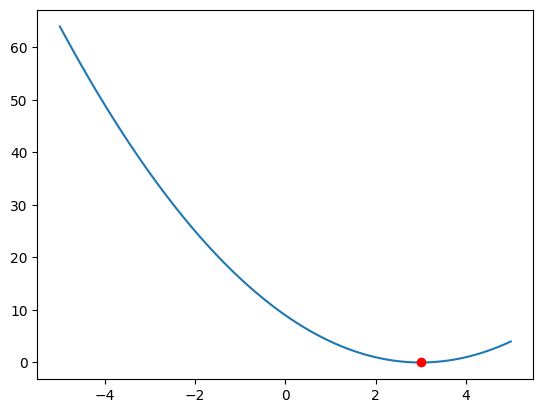

In [20]:
# Representation of global minimizer if a gradient equals 0, using (x - 3)^2 as the polynomial -- as gradient equals 0 if x = 3

import numpy as np
import scipy.optimize as opt

polynomial = np.poly1d([1.0, -6.0, 9.0])    ## converts (x - 3)^2 --> x^2 - 6x + 9

x0 = 3.0    ## starting point
results = opt.minimize(polynomial, x0)
print("The global minimizer of the polynomial (x - 3)^2 is ", results.x)


## representing this in a graph
import matplotlib.pylab as plt

x = np.linspace(-5, 5, 100)
plt.plot(x, polynomial(x))
plt.plot(results.x, polynomial(results.x), 'ro')
plt.show()

## 3.3.3 - Gradient descent

Gradient descent is an iterative optimization algorithm for finding a local minimum of a differentiable function -- finds all stationary points of $f : R^d -> R$ which are continuosuly differnetiable (aka those $x$'s such that $∇f (x) = 0$) and choose the $x$ among them that produces the smallest value of $f(x)$

### 3.3.3.1 - Steepest descent

The steepest descent approach is to find smaller values of f by successively
following directions in which f decreases. As we have seen in the proof of
the first-order necessary condition, $−∇f$ provides such a direction.

**Theorem 3.3.23.** Suppose that $f : Rd → R$ is twice continuously differentiable. The step size is chosen to minimize

$$α_k = arg\;min_{α>0} f(x^k − α∇f (x^k)).$$

Then steepest descent started from any $x^0$ produces a sequence $x^k , k = 1, 2, . . .$ such that if $∇f (xk) != 0$, then

$$f (xk+1) ≤ f (xk), ∀k ≥ 1.$$

The local minimum of the function (x^2 - 21)^3 is 0.0026334228098155834


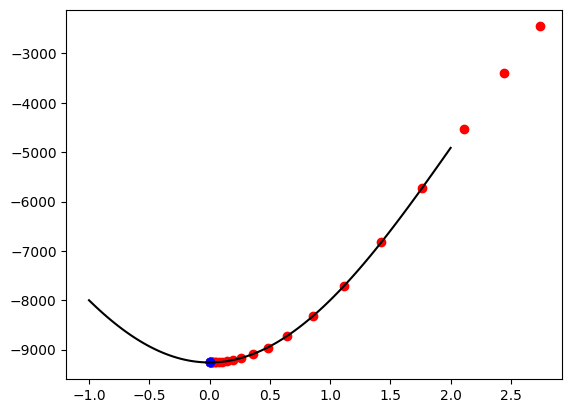

In [39]:
# Gradient Descent representation with previous example of representing 'descent direction`
import matplotlib.pylab as plt

## repeat of gradient descent function from before
def descent():
  current_x = 3      ## descent algorithm starts at x = 1
  rate = 0.0001        ## learning rate
  precision = 0.001
  previous_step_size = 1
  max_iters = 10000  ## max iterations
  iters = 0          ## iteration count
  df = lambda x: 6*x*(x**2 - 21)**2    ## test function (derivative)
  f = lambda x: (x**2 - 21)**3         ## original test function

  while previous_step_size > precision and iters < max_iters:
      prev_x = current_x
      current_x = current_x - rate * df(prev_x)           ## gradient descent
      previous_step_size = abs(current_x - prev_x)    ## Changing x
      iters = iters + 1
      plt.scatter(current_x, f(current_x), c = 'red')

  plt.scatter(current_x, f(current_x), c = 'blue')    ## Global min found!!
  return current_x;

print("The local minimum of the function (x^2 - 21)^3 is " + str(descent()))
x = np.linspace(-1, 2, 100)
y = (x**2 - 21)**3
plt.plot(x, y, c = 'black')
plt.show()